# Step 2: Exploratory Data Analysis (EDA)

**Dataset:** `data/trends_cleaned.csv`  
**Goal:** Understand trends over time, top countries, popular categories, top global searches, and feature correlations using simple code and clear graphs.


## 1. Load Cleaned Data & Quick Summary


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/trends_cleaned.csv")

print("Shape:", df.shape)
print("Years:", df["year"].min(), "to", df["year"].max())
print("Unique locations:", df["location"].nunique())
print("Unique categories:", df["category_clean"].nunique())
print("Unique queries:", df["query"].nunique())

print("\nGlobal vs Country-Specific rows:")
print(df["is_global"].value_counts())

print("\nRank counts (1 to 5):")
print(df["rank"].value_counts().sort_index())

print("\nWriting scripts:")
print(df["script"].value_counts())


Shape: (26945, 11)
Years: 2001 to 2020
Unique locations: 83
Unique categories: 2366
Unique queries: 18430

Global vs Country-Specific rows:
is_global
False    25810
True      1135
Name: count, dtype: int64

Rank counts (1 to 5):
rank
1    5389
2    5389
3    5389
4    5389
5    5389
Name: count, dtype: int64

Writing scripts:
script
Latin            22860
Chinese/CJK       1560
Cyrillic          1150
Arabic             435
Thai               404
Hebrew             397
Greek              115
Other/Numeric       24
Name: count, dtype: int64


## 2. Trend Entries per Year


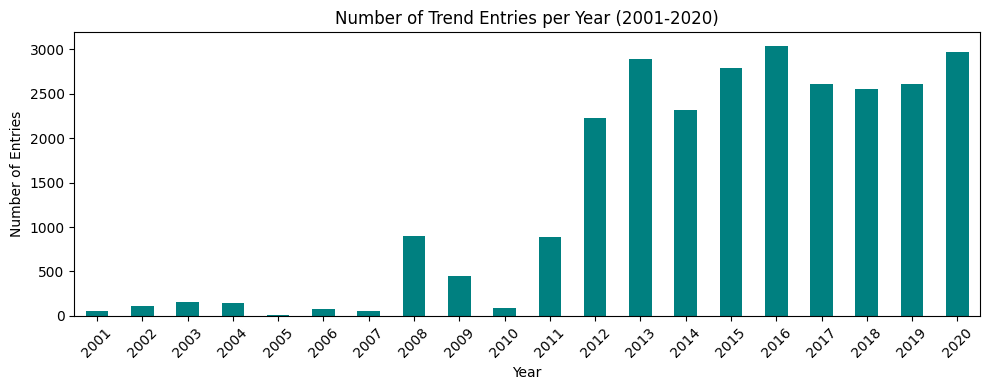

In [2]:
yearly_counts = df["year"].value_counts().sort_index()

plt.figure(figsize=(10, 4))
yearly_counts.plot(kind="bar", color="teal")
plt.title("Number of Trend Entries per Year (2001-2020)")
plt.xlabel("Year")
plt.ylabel("Number of Entries")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("visualizations/02_entries_per_year.png", dpi=150)
plt.show()


## 3. Top 10 Countries by Number of Entries


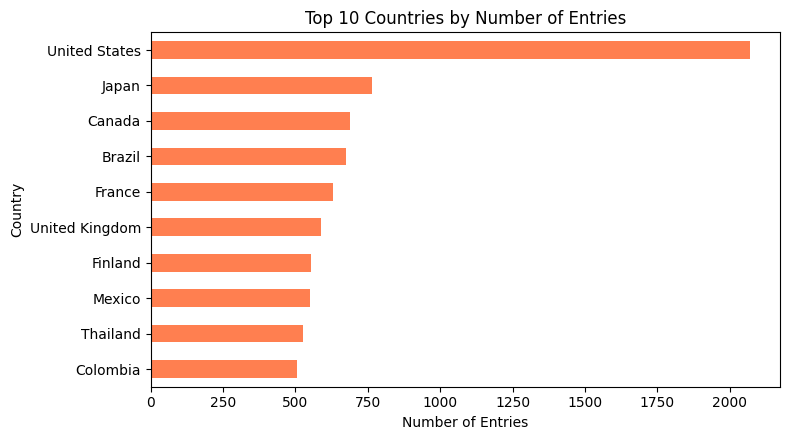

In [3]:
country_df = df[df["is_global"] == False]
top10_countries = country_df["location"].value_counts().head(10)

plt.figure(figsize=(8, 4.5))
top10_countries.sort_values().plot(kind="barh", color="coral")
plt.title("Top 10 Countries by Number of Entries")
plt.xlabel("Number of Entries")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig("visualizations/03_top10_countries.png", dpi=150)
plt.show()


## 4. Top 10 Trend Categories


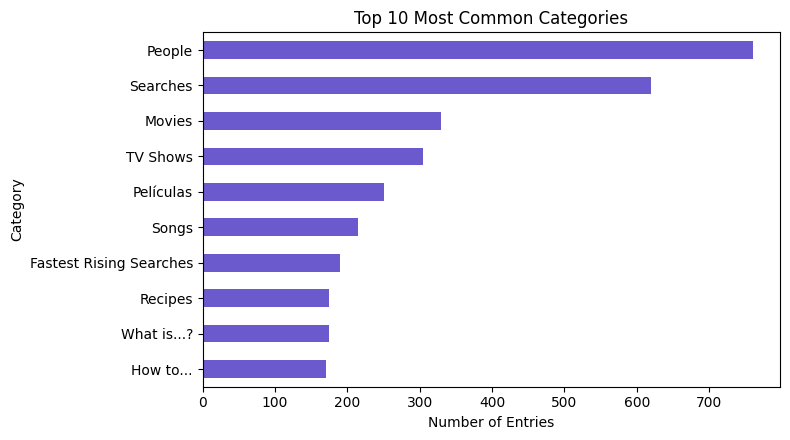

In [4]:
top10_cats = df["category"].value_counts().head(10)

plt.figure(figsize=(8, 4.5))
top10_cats.sort_values().plot(kind="barh", color="slateblue")
plt.title("Top 10 Most Common Categories")
plt.xlabel("Number of Entries")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig("visualizations/04_top10_categories.png", dpi=150)
plt.show()


## 5. Top 10 Most-Repeated Global Search Queries


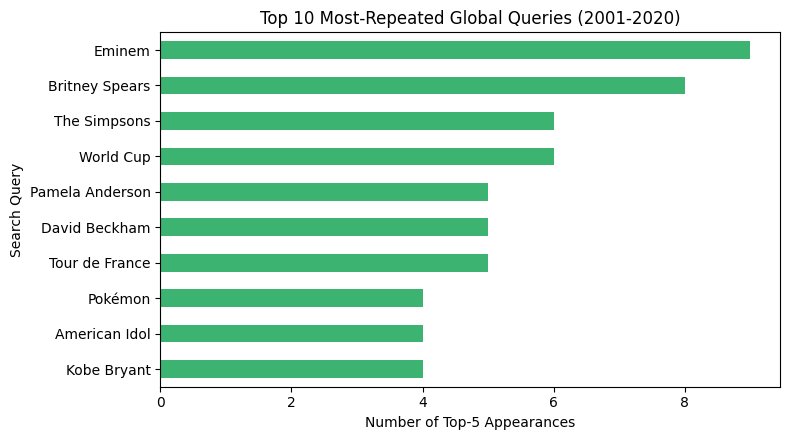

In [5]:
global_df = df[df["is_global"] == True]
top10_global = global_df["query"].value_counts().head(10)

plt.figure(figsize=(8, 4.5))
top10_global.sort_values().plot(kind="barh", color="mediumseagreen")
plt.title("Top 10 Most-Repeated Global Queries (2001-2020)")
plt.xlabel("Number of Top-5 Appearances")
plt.ylabel("Search Query")
plt.tight_layout()
plt.savefig("visualizations/05_top10_global_queries.png", dpi=150)
plt.show()


## 6. Correlation Heatmap


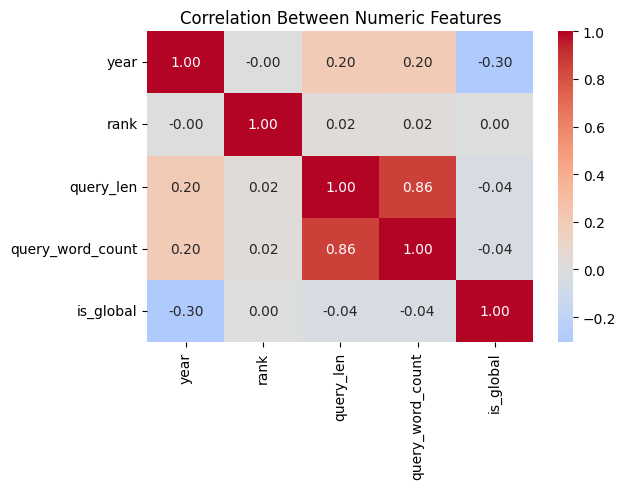

In [6]:
corr_df = df[["year", "rank", "query_len", "query_word_count"]].copy()
corr_df["is_global"] = df["is_global"].astype(int)

plt.figure(figsize=(6.5, 5))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Numeric Features")
plt.tight_layout()
plt.savefig("visualizations/06_correlation_heatmap.png", dpi=150)
plt.show()


## 7. Key Takeaways

- **Time Growth:** Early years (2001–2010) have fewer entries, while 2012–2020 have much larger coverage.
- **Top Country:** The United States has the most entries (2,070), followed by Japan (765) and Canada (690).
- **Balanced Rank:** Ranks `1` through `5` appear equally (5,389 times each).
- **Rank Correlation:** Numeric metadata (`year`, `query_len`, `is_global`) has almost zero correlation with `rank`, meaning the actual `query` text matters most for predicting rank.
